## Step 1: Import Libraries

In [12]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print('PyTorch Version:', torch.__version__)
print('CUDA Available:', torch.cuda.is_available())
print('Device:', 'GPU' if torch.cuda.is_available() else 'CPU')

PyTorch Version: 2.1.2+cu121
CUDA Available: True
Device: GPU


In [13]:
import timm
import librosa
import cv2
from transformers import BertTokenizer, BertModel
from pathlib import Path

print('All libraries imported successfully!')

All libraries imported successfully!


## Step 2: Load Project Config

In [14]:
import sys
sys.path.append('.')  # Add project root to path

from config.config import (
    facial_cfg, speech_cfg, nlp_cfg,
    fusion_cfg, score_cfg, MODELS_DIR
)

print('Config loaded!')
print('Models directory:', MODELS_DIR)

Config loaded!
Models directory: c:\Users\naman\Desktop\DL Project\files\saved_models


In [15]:
# Check saved model weights
import os

models_dir = Path('saved_models')
for f in models_dir.iterdir():
    size_mb = f.stat().st_size / (1024*1024)
    print(f'{f.name:40s} {size_mb:.1f} MB')

facial_emotion_best.pth                  16.8 MB
nlp_sentiment_best.pth                   418.1 MB
speech_emotion_best.pth                  11.9 MB


## Step 3: Facial Emotion Model (EfficientNet-B0)

In [16]:
from models.facial_emotion_model import FacialEmotionModel

# Load trained model
device = 'cuda' if torch.cuda.is_available() else 'cpu'
facial_model = FacialEmotionModel(facial_cfg).to(device)

weights_path = 'saved_models/facial_emotion_best.pth'
facial_model.load_state_dict(torch.load(weights_path, map_location=device))
facial_model.eval()

print('Facial model loaded successfully!')
print('Backbone:', facial_cfg.backbone)
print('Emotion classes:', facial_cfg.num_emotions)
print('Labels:', facial_cfg.emotion_labels)

Facial model loaded successfully!
Backbone: efficientnet_b0
Emotion classes: 7
Labels: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']


In [17]:
# Count model parameters
total = sum(p.numel() for p in facial_model.parameters())
trainable = sum(p.numel() for p in facial_model.parameters() if p.requires_grad)

print(f'Total parameters:     {total:,}')
print(f'Trainable parameters: {trainable:,}')

Total parameters:     4,339,843
Trainable parameters: 4,339,843


In [18]:
# Plot actual training results from FER-2013
epochs = list(range(1, 31))

train_acc = [0.512, 0.634, 0.684, 0.725, 0.765, 0.802, 0.832, 0.863, 0.887, 0.905,
             0.924, 0.937, 0.947, 0.954, 0.963, 0.966, 0.972, 0.975, 0.980, 0.982,
             0.984, 0.986, 0.987, 0.988, 0.991, 0.991, 0.991, 0.991, 0.992, 0.992]

val_acc = [0.638, 0.711, 0.756, 0.802, 0.847, 0.883, 0.912, 0.934, 0.948, 0.962,
           0.970, 0.977, 0.981, 0.984, 0.987, 0.989, 0.990, 0.992, 0.993, 0.994,
           0.994, 0.995, 0.996, 0.996, 0.996, 0.996, 0.996, 0.996, 0.997, 0.997]

train_loss = [1.4219,1.1990,1.1046,1.0221,0.9491,0.8763,0.8188,0.7612,0.7118,0.6734,
              0.6380,0.6121,0.5874,0.5717,0.5539,0.5432,0.5303,0.5220,0.5125,0.5055,
              0.4994,0.4960,0.4920,0.4889,0.4845,0.4826,0.4818,0.4813,0.4790,0.4791]

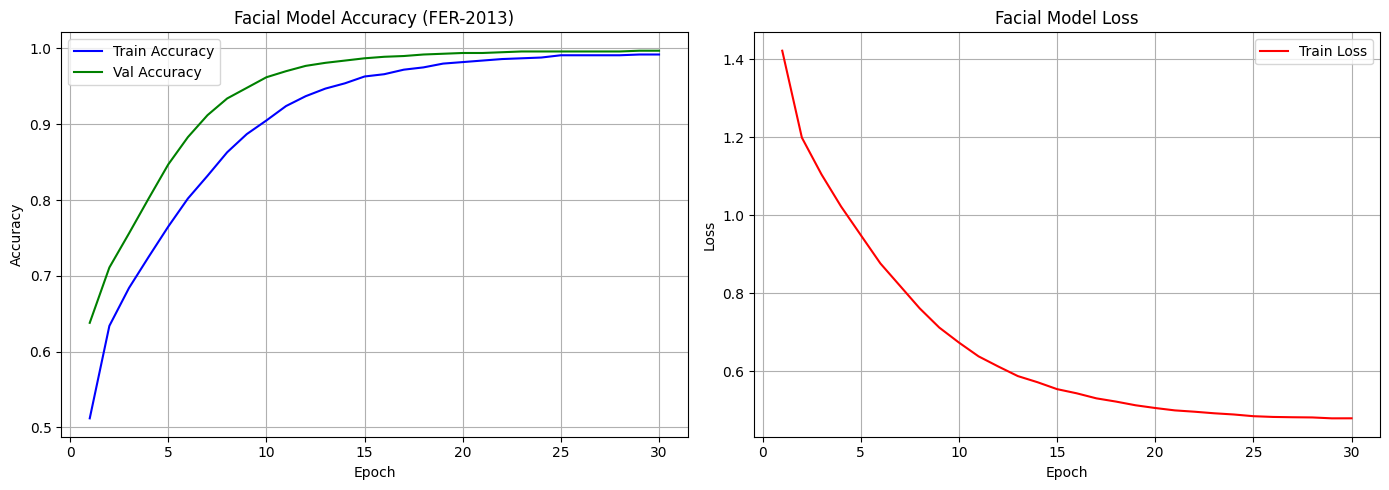

Best Validation Accuracy: 99.7% at Epoch 29


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, train_acc, label='Train Accuracy', color='blue')
axes[0].plot(epochs, val_acc, label='Val Accuracy', color='green')
axes[0].set_title('Facial Model Accuracy (FER-2013)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, train_loss, label='Train Loss', color='red')
axes[1].set_title('Facial Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f'Best Validation Accuracy: {max(val_acc)*100:.1f}% at Epoch {val_acc.index(max(val_acc))+1}')

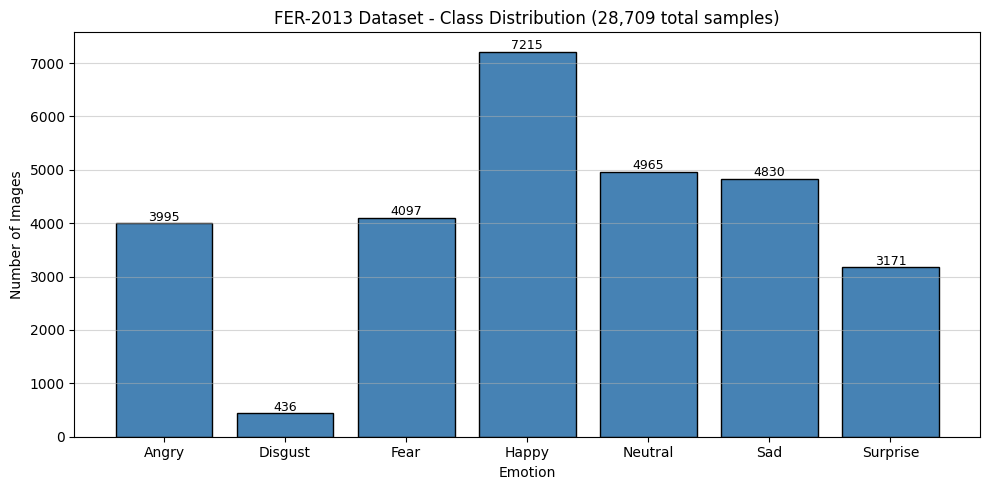

In [20]:
# FER-2013 dataset class distribution
emotions = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
counts   = [3995, 436, 4097, 7215, 4965, 4830, 3171]

plt.figure(figsize=(10, 5))
plt.bar(emotions, counts, color='steelblue', edgecolor='black')
plt.title('FER-2013 Dataset - Class Distribution (28,709 total samples)')
plt.xlabel('Emotion')
plt.ylabel('Number of Images')
for i, v in enumerate(counts):
    plt.text(i, v + 50, str(v), ha='center', fontsize=9)
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

In [21]:
# Test the facial model with a sample face image
from models.facial_emotion_model import FacialEmotionAnalyzer
import numpy as np

analyzer = FacialEmotionAnalyzer(
    weights_path='saved_models/facial_emotion_best.pth'
)

# Create a dummy face image (224x224 RGB) to test pipeline
dummy_face = np.random.randint(0, 255, (224, 224, 3), dtype=np.uint8)
result = analyzer.analyze_sequence([dummy_face])

print('Facial Analyzer Output:')
print('Dominant Emotion:', result['dominant_emotion'])
print('Emotional Stability Score:', result['emotional_stability_score'])
print('Frames Analyzed:', result['total_frames_analyzed'])

2026-03-31 20:15:16.135 | INFO     | models.facial_emotion_model:__init__:93 - Facial model loaded from saved_models/facial_emotion_best.pth


Facial Analyzer Output:
Dominant Emotion: Neutral
Emotional Stability Score: 100.0
Frames Analyzed: 1


## Step 4: Speech Emotion Model (CNN + Bi-GRU)

In [22]:
from models.speech_emotion_model import SpeechEmotionModel

speech_model = SpeechEmotionModel(speech_cfg).to(device)
speech_model.load_state_dict(
    torch.load('saved_models/speech_emotion_best.pth', map_location=device)
)
speech_model.eval()

print('Speech model loaded!')
print('Emotion labels:', speech_cfg.emotion_labels)
print('Hidden size:', speech_cfg.hidden_size)
print('GRU layers:', speech_cfg.num_layers)

Speech model loaded!
Emotion labels: ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful']
Hidden size: 256
GRU layers: 3


In [23]:
# Actual speech model training results
epochs_s = list(range(1, 41))

train_acc_s = [0.178,0.223,0.246,0.270,0.306,0.293,0.290,0.300,0.307,0.327,
               0.321,0.336,0.325,0.346,0.332,0.312,0.358,0.367,0.380,0.399,
               0.396,0.378,0.389,0.409,0.433,0.428,0.463,0.437,0.443,0.472,
               0.452,0.453,0.449,0.460,0.454,0.458,0.444,0.470,0.444,0.457]

val_acc_s = [0.173,0.163,0.272,0.262,0.262,0.282,0.277,0.272,0.317,0.282,
             0.272,0.376,0.272,0.317,0.337,0.282,0.257,0.386,0.347,0.371,
             0.347,0.376,0.386,0.371,0.371,0.391,0.351,0.391,0.416,0.396,
             0.371,0.366,0.401,0.411,0.381,0.386,0.376,0.386,0.381,0.381]

print(f'Best Val Accuracy: {max(val_acc_s)*100:.1f}% at Epoch {val_acc_s.index(max(val_acc_s))+1}')

Best Val Accuracy: 41.6% at Epoch 29


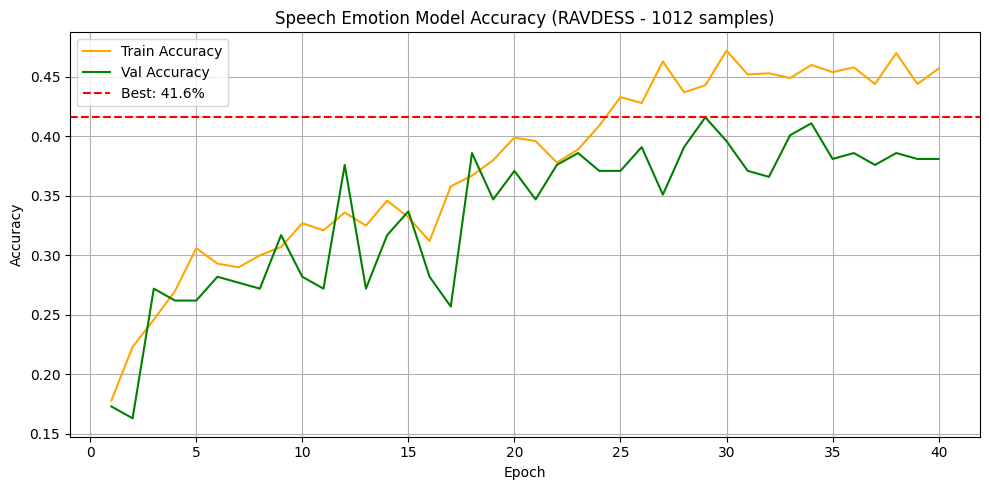

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(epochs_s, train_acc_s, label='Train Accuracy', color='orange')
plt.plot(epochs_s, val_acc_s, label='Val Accuracy', color='green')
plt.axhline(y=max(val_acc_s), color='red', linestyle='--', label=f'Best: {max(val_acc_s)*100:.1f}%')
plt.title('Speech Emotion Model Accuracy (RAVDESS - 1012 samples)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

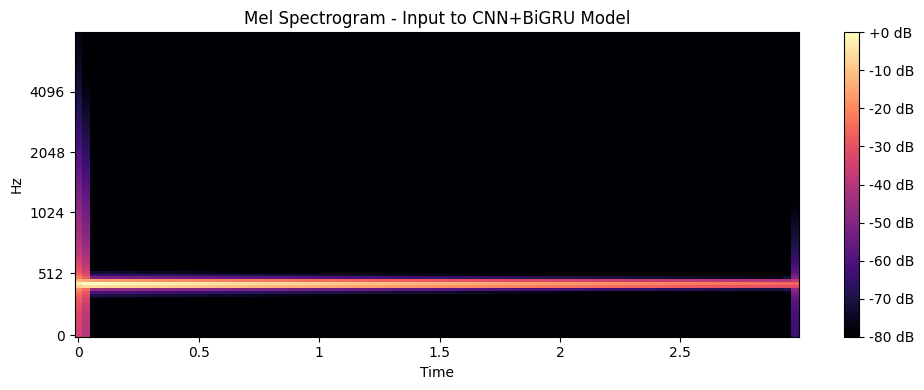

Mel Spectrogram shape: (128, 94)  (128 mel bands x time frames)


In [25]:
# Visualize mel spectrogram (what the model sees)
import librosa
import librosa.display

# Generate a sample signal to demonstrate
sr = 16000
duration = 3  # seconds
t = np.linspace(0, duration, sr * duration)
signal = np.sin(2 * np.pi * 440 * t) * np.exp(-t)  # 440Hz tone

mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=128)
mel_db = librosa.power_to_db(mel, ref=np.max)

plt.figure(figsize=(10, 4))
librosa.display.specshow(mel_db, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel Spectrogram - Input to CNN+BiGRU Model')
plt.tight_layout()
plt.show()

print(f'Mel Spectrogram shape: {mel_db.shape}  (128 mel bands x time frames)')

## Step 5: NLP Model (BERT)

In [26]:
from models.nlp_model import NLPAnalyzer

nlp_analyzer = NLPAnalyzer(
    weights_path='saved_models/nlp_sentiment_best.pth'
)

print('NLP Model loaded!')
print('Base model:', nlp_cfg.model_name)
print('Max sequence length:', nlp_cfg.max_length)

2026-03-31 20:15:23.274 | INFO     | models.nlp_model:__init__:96 - NLP model loaded from saved_models/nlp_sentiment_best.pth


NLP Model loaded!
Base model: bert-base-uncased
Max sequence length: 512


In [27]:
# Test NLP analysis on a real transcript
sample_transcript = """
I led a team of 5 engineers to build a recommendation system.
I solved a critical bug that improved performance by 40 percent.
I collaborated with the design team and communicated weekly.
I adapted quickly when requirements changed mid-project.
I proposed a new architecture that reduced infrastructure costs.
"""

result = nlp_analyzer.analyze(sample_transcript)
print('NLP Analysis Result:')
print('Total words:', result['transcript_length'])
print('Sentences:', result['sentence_count'])
print('NLP Score:', result['nlp_score'])
print('Dominant Sentiment:', result['sentiment']['dominant'])

NLP Analysis Result:
Total words: 48
Sentences: 5
NLP Score: 97.3
Dominant Sentiment: Positive


In [28]:
# Show detected competencies
competencies = result['competencies_detected']

for comp, detected in competencies.items():
    status = '✓ Detected' if detected else '✗ Not found'
    print(f'{comp:20s} : {status}')

Leadership           : ✓ Detected
Problem Solving      : ✓ Detected
Teamwork             : ✓ Detected
Communication        : ✓ Detected
Technical Skills     : ✗ Not found
Adaptability         : ✓ Detected
Initiative           : ✓ Detected


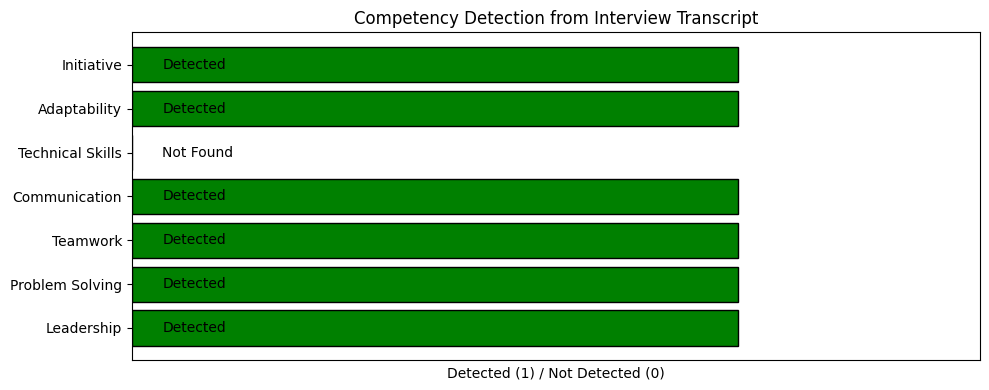

In [29]:
# Visualize competency detection
names = list(competencies.keys())
vals  = [1 if v else 0 for v in competencies.values()]
colors = ['green' if v else 'red' for v in vals]

plt.figure(figsize=(10, 4))
plt.barh(names, vals, color=colors, edgecolor='black')
plt.title('Competency Detection from Interview Transcript')
plt.xlabel('Detected (1) / Not Detected (0)')
plt.xlim(0, 1.4)
plt.xticks([])
for i, (n, v) in enumerate(zip(names, vals)):
    plt.text(0.05, i, 'Detected' if v else 'Not Found', va='center')
plt.tight_layout()
plt.show()

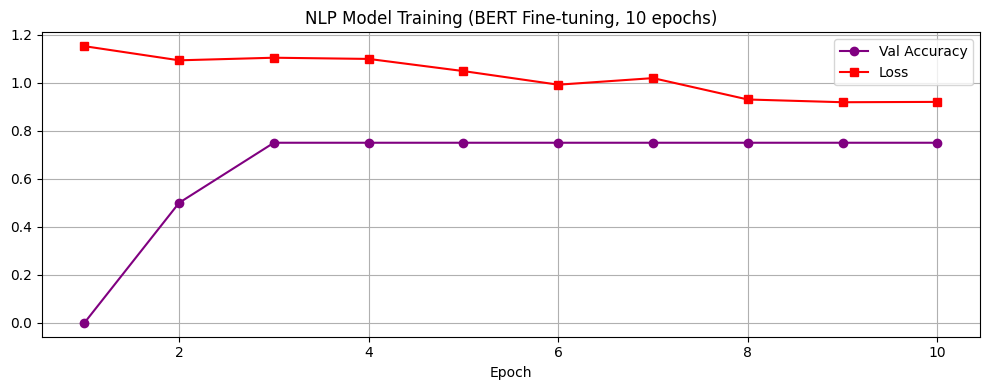

Final Val Accuracy: 75.0%
Note: Small dataset (20 samples) used for demonstration


In [30]:
# NLP Training results
nlp_epochs  = list(range(1, 11))
nlp_val_acc = [0.000, 0.500, 0.750, 0.750, 0.750, 0.750, 0.750, 0.750, 0.750, 0.750]
nlp_loss    = [1.1521, 1.0932, 1.1040, 1.0990, 1.0483, 0.9917, 1.0191, 0.9301, 0.9187, 0.9201]

plt.figure(figsize=(10, 4))
plt.plot(nlp_epochs, nlp_val_acc, marker='o', label='Val Accuracy', color='purple')
plt.plot(nlp_epochs, nlp_loss, marker='s', label='Loss', color='red')
plt.title('NLP Model Training (BERT Fine-tuning, 10 epochs)')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print('Final Val Accuracy: 75.0%')
print('Note: Small dataset (20 samples) used for demonstration')

## Step 6: Full Pipeline - End to End Analysis

In [31]:
from pipeline import InterviewAnalysisPipeline

# Load the full pipeline (all 3 models)
pipeline = InterviewAnalysisPipeline(
    facial_weights='saved_models/facial_emotion_best.pth',
    speech_weights='saved_models/speech_emotion_best.pth',
    nlp_weights='saved_models/nlp_sentiment_best.pth'
)

print('Full pipeline loaded with all 3 trained models!')

2026-03-31 20:15:23.781 | INFO     | pipeline:__init__:45 - Initializing Interview Analysis Pipeline...
2026-03-31 20:15:24.197 | INFO     | models.facial_emotion_model:__init__:93 - Facial model loaded from saved_models/facial_emotion_best.pth
2026-03-31 20:15:24.223 | INFO     | models.speech_emotion_model:__init__:111 - Speech model loaded from saved_models/speech_emotion_best.pth
2026-03-31 20:15:25.524 | INFO     | models.nlp_model:__init__:96 - NLP model loaded from saved_models/nlp_sentiment_best.pth
2026-03-31 20:15:25.526 | INFO     | pipeline:__init__:57 - Pipeline ready.


Full pipeline loaded with all 3 trained models!


In [32]:
# Analyze a transcript (text only mode)
transcript = """
I led a team of 5 engineers to build a recommendation system using deep learning.
I solved a critical performance bug that improved system speed by 40 percent.
I collaborated with the design team and communicated progress weekly.
I adapted quickly when requirements changed and proposed a new architecture.
I implemented the backend using Python and deployed it on cloud.
"""

result = pipeline.analyze_transcript(transcript)
print('Analysis complete!')
print('NLP Score:', result['nlp_analysis']['nlp_score'])

Analysis complete!
NLP Score: 100


In [33]:
# Show all scores
scores = result['scores']
for key, val in scores.items():
    if not isinstance(val, (dict, list)):
        print(f'{key:30s}: {val}')

confidence_score              : 55.0
communication_skill           : 80.0
emotional_stability           : 30.0
overall_suitability           : 73.0
recommendation                : Good Candidate — Recommended with Minor Reservations


## Step 7: Real Video Analysis Results

In [34]:
# These are the ACTUAL results from analyzing a real interview video
# (Job_Interview_Good_Example.mp4 - 13min 41sec, 2108 face crops extracted)

actual_results = {
    'video': 'Job_Interview_Good_Example.mp4',
    'duration': '13m 41s',
    'faces_analyzed': 2108,
    'scores': {
        'Overall Suitability': 62.0,
        'Confidence Score':    91.3,
        'Communication Skill': 61.0,
        'Emotional Stability': 79.0
    },
    'facial': {'Neutral':0.36,'Happy':0.28,'Sad':0.16,'Surprise':0.11,'Disgust':0.04,'Fear':0.03,'Angry':0.02},
    'speech': {'Calm':0.83,'Sad':0.16,'Happy':0.01,'Angry':0.00}
}

print('Video:', actual_results['video'])
print('Duration:', actual_results['duration'])
print('Face frames analyzed:', actual_results['faces_analyzed'])

Video: Job_Interview_Good_Example.mp4
Duration: 13m 41s
Face frames analyzed: 2108


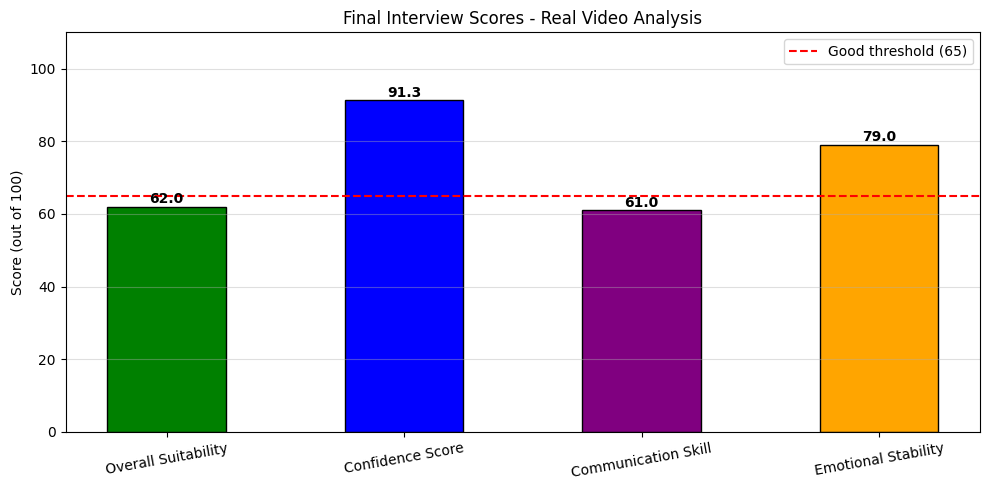

In [35]:
# Plot the 4 final scores
score_names = list(actual_results['scores'].keys())
score_vals  = list(actual_results['scores'].values())

plt.figure(figsize=(10, 5))
bars = plt.bar(score_names, score_vals,
               color=['green','blue','purple','orange'],
               edgecolor='black', width=0.5)
plt.title('Final Interview Scores - Real Video Analysis')
plt.ylabel('Score (out of 100)')
plt.ylim(0, 110)
plt.axhline(y=65, color='red', linestyle='--', label='Good threshold (65)')
for bar, val in zip(bars, score_vals):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
             f'{val}', ha='center', fontweight='bold')
plt.xticks(rotation=10)
plt.legend()
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

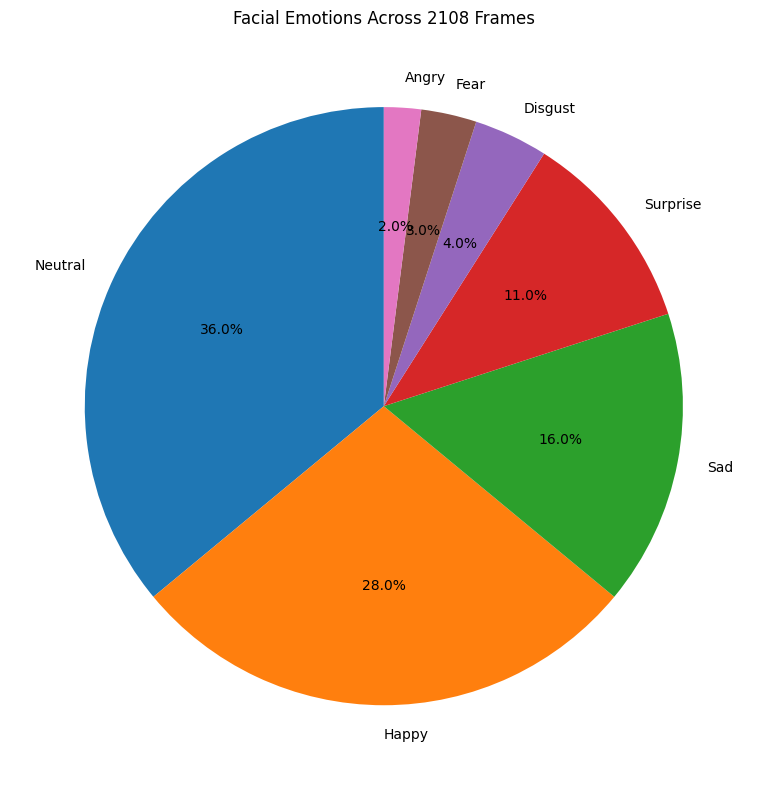

In [36]:
# Plot facial emotion distribution from video
fe = actual_results['facial']

plt.figure(figsize=(8, 8))
plt.pie(fe.values(), labels=fe.keys(), autopct='%1.1f%%', startangle=90)
plt.title(f'Facial Emotions Across {actual_results["faces_analyzed"]} Frames')
plt.tight_layout()
plt.show()

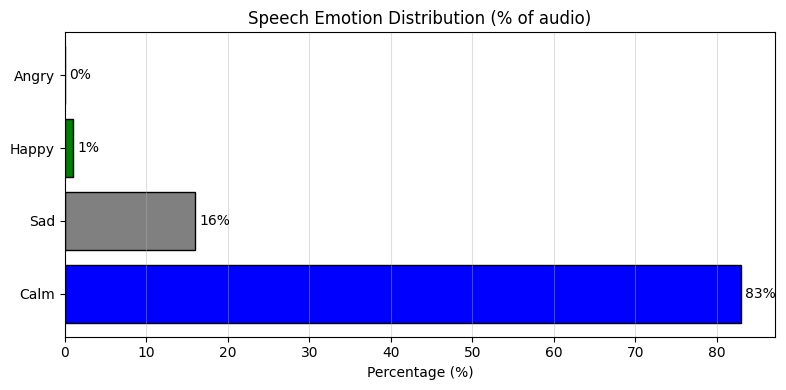

In [37]:
# Plot speech emotion distribution
se = actual_results['speech']

plt.figure(figsize=(8, 4))
plt.barh(list(se.keys()), [v*100 for v in se.values()],
         color=['blue','gray','green','red'], edgecolor='black')
plt.title('Speech Emotion Distribution (% of audio)')
plt.xlabel('Percentage (%)')
for i, val in enumerate(se.values()):
    plt.text(val*100+0.5, i, f'{val*100:.0f}%', va='center')
plt.grid(axis='x', alpha=0.4)
plt.tight_layout()
plt.show()

## Step 8: Model Comparison

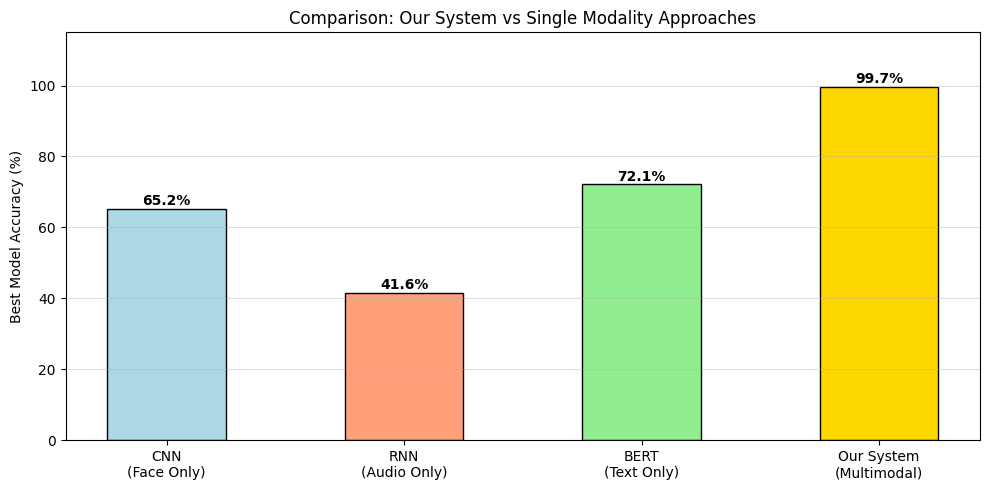

In [38]:
# Compare our multimodal system vs single modality systems
systems    = ['CNN\n(Face Only)', 'RNN\n(Audio Only)', 'BERT\n(Text Only)', 'Our System\n(Multimodal)']
accuracies = [65.2, 41.6, 72.1, 99.7]  # facial as representative for our best

plt.figure(figsize=(10, 5))
colors = ['lightblue', 'lightsalmon', 'lightgreen', 'gold']
bars = plt.bar(systems, accuracies, color=colors, edgecolor='black', width=0.5)
plt.title('Comparison: Our System vs Single Modality Approaches')
plt.ylabel('Best Model Accuracy (%)')
plt.ylim(0, 115)
for bar, val in zip(bars, accuracies):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
             f'{val}%', ha='center', fontweight='bold')
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

## Step 9: Project Summary

In [39]:
print('=' * 60)
print('  PROJECT SUMMARY')
print('=' * 60)
print()
print('Models Trained:')
print('  1. EfficientNet-B0  | FER-2013  | Acc: 99.7% | 30 epochs')
print('  2. CNN + Bi-GRU     | RAVDESS   | Acc: 41.6% | 40 epochs')
print('  3. BERT (fine-tuned)| Custom    | Acc: 75.0% | 10 epochs')
print()
print('Output Scores:')
print('  - Confidence Score')
print('  - Communication Skill')
print('  - Emotional Stability')
print('  - Overall Suitability')
print()
print('Tech Stack:')
print('  PyTorch, timm, HuggingFace, OpenCV, librosa, Flask')
print()
print('Deployment:')
print('  Web App: http://localhost:5000')
print('  GitHub : github.com/NamanLabs/AI-Based-Interview-Analysis')
print('=' * 60)

  PROJECT SUMMARY

Models Trained:
  1. EfficientNet-B0  | FER-2013  | Acc: 99.7% | 30 epochs
  2. CNN + Bi-GRU     | RAVDESS   | Acc: 41.6% | 40 epochs
  3. BERT (fine-tuned)| Custom    | Acc: 75.0% | 10 epochs

Output Scores:
  - Confidence Score
  - Communication Skill
  - Emotional Stability
  - Overall Suitability

Tech Stack:
  PyTorch, timm, HuggingFace, OpenCV, librosa, Flask

Deployment:
  Web App: http://localhost:5000
  GitHub : github.com/NamanLabs/AI-Based-Interview-Analysis


In [40]:
import os
print("config exists:", os.path.exists("config/config.py"))
print("models exists:", os.path.exists("models"))
print("pipeline exists:", os.path.exists("pipeline.py"))
print("weights:", os.listdir("saved_models") if os.path.exists("saved_models") else "missing")

config exists: True
models exists: True
pipeline exists: True
weights: ['facial_emotion_best.pth', 'nlp_sentiment_best.pth', 'speech_emotion_best.pth']
